# South African Education Dataset — Step 2: Data Cleaning and Preparation

**Input file:** `School_Data_CSV.csv`  
**Previous stage:** Step 1 — Exploratory Data Analysis (EDA)

## Goal
Prepare a documented, analysis-ready working dataset while retaining the original data for traceability.

### Important rules
- Never overwrite the source CSV.
- Keep `df_raw` unchanged and make cleaning changes in `df_clean`.
- Do not remove rows just because fields are missing.
- Do not assume repeated identifiers are duplicates.
- Treat identifier columns as strings, not measurements.
- Keep ambiguous codes such as `99` in identifier fields until the data dictionary confirms their meaning.
- Keep a cleaning log so every transformation is auditable.


## Step 2 algorithm

1. Import libraries and load the CSV with encoding fallback.
2. Keep an unchanged raw copy.
3. Standardise column names and trim leading/trailing whitespace in text fields.
4. Convert known placeholder values (such as `.`, `NOT APPLICABLE`, `TO BE UPDATED`, and `UNKNOWN`) to missing values **only in descriptive fields where they clearly represent unavailable information**.
5. Preserve identifier values as strings and flag suspicious placeholder-like codes for review.
6. Standardise quintile labels where meaning is clear (`Q1` → `1`, etc.); flag non-standard categories rather than guessing.
7. Convert longitude and latitude to numeric values; unparseable values become missing and are counted in the cleaning log.
8. Flag coordinate pairs outside a broad South African plausibility range; do not delete them automatically.
9. Identify exact duplicate rows and possible repeated identifiers for review.
10. Save the prepared dataset, quality report, and cleaning log to output files.

**Output:** `School_Data_Cleaned_Step2.csv`, `Step2_Cleaning_Log.csv`, and `Step2_Quality_Report.csv`.


In [1]:
# 1. Import libraries and configure paths

from pathlib import Path
import pandas as pd
import numpy as np

pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 100)

INPUT_PATH = Path("School_Data_CSV.csv")
OUTPUT_DIR = Path("step2_outputs")
OUTPUT_DIR.mkdir(exist_ok=True)


In [2]:
# 2. Load the CSV safely

def load_csv_with_encoding_fallback(file_path):
    encodings = ["utf-8", "utf-8-sig", "cp1252", "latin1"]
    last_error = None
    for encoding in encodings:
        try:
            data = pd.read_csv(file_path, encoding=encoding, low_memory=False)
            print(f"Loaded with encoding: {encoding}")
            return data
        except UnicodeDecodeError as exc:
            last_error = exc
    raise UnicodeError(f"Could not decode file. Last error: {last_error}")

if not INPUT_PATH.exists():
    raise FileNotFoundError(
        f"Could not find {INPUT_PATH.resolve()}. Place the CSV beside this notebook "
        "or update INPUT_PATH."
    )

df_raw = load_csv_with_encoding_fallback(INPUT_PATH)
df_clean = df_raw.copy(deep=True)

print(f"Raw shape: {df_raw.shape}")
display(df_raw.head())


Loaded with encoding: cp1252
Raw shape: (199853, 9)


,emisno,centername,institution_name,centreno,quintile,ward_id,street_address,new_long,new_lat
0,200100005,ABERDEEN SECONDARY SCHOOL (20),ABERDEEN SECONDARY SCHOOL,4201001,3,21001001,"10 PARLIAMENT STREET, ABERDEEN, 6270",24.06183,-32.47385
1,200100012,ADELAIDE GYMNASIUM,ADELAIDE GYMNASIUM,4171044,4,21208001,"WELSH STREET, ADELAIDE, 5760",26.29476,-32.71036
2,200100018,AEROVILLE(SOMERSET EAST) (20),AEROVILLE SECONDARY SCHOOL,4201002,3,21002002,"PERSEVERANCE DR, SOMERSET EAST, 5850",25.60073,-32.74592
3,200100019,Al Azhar Institute,AL-AZHAR PRIMARY SCHOOL,4222001,NOT APPLICABLE,29500009,"42 RUDOLPH STREET, MALABAR, PORT ELIZABETH, 6000",25.53563,-33.91924
4,200100021,ALEXANDER ROAD HIGH SCHOOL,ALEXANDER ROAD HIGH SCHOOL,4221002,5,29300007,"ALEXANDER ROAD, NEWTON PARK, PORT ELIZABETH, 6055",25.57181,-33.94147


## 3. Create a cleaning log

Each transformation or diagnostic is recorded below. This is useful for explaining and defending data preparation decisions in a report.


In [3]:
cleaning_log = []

def log_action(step, column, affected_count, action, reason):
    cleaning_log.append({
        "step": step,
        "column": column,
        "affected_count": int(affected_count),
        "action": action,
        "reason": reason
    })

# Normalise column labels only (not the values).
original_columns = df_clean.columns.tolist()
df_clean.columns = (
    df_clean.columns.astype(str)
    .str.strip()
    .str.lower()
    .str.replace(r"\\s+", "_", regex=True)
)
log_action(
    "Column labels", "ALL", len(original_columns),
    "Trimmed and standardised column names",
    "Makes column references consistent; original names are simple and already mostly standard."
)

print(df_clean.columns.tolist())


['emisno', 'centername', 'institution_name', 'centreno', 'quintile', 'ward_id', 'street_address', 'new_long', 'new_lat']


## 4. Trim whitespace and standardise missing-value placeholders

The dataset contains placeholder-like values in fields such as names, addresses, quintile, and coordinates. These are not informative measurements. We convert common textual placeholders to actual missing values in those fields only.

**We deliberately do not replace `99` in identifier columns automatically**, because its official meaning is not confirmed. Such values will be flagged for review.


In [4]:
# Descriptive fields where common placeholders indicate unavailable information.
descriptive_fields = [
    "centername", "institution_name", "street_address", "quintile",
    "new_long", "new_lat"
]
descriptive_fields = [c for c in descriptive_fields if c in df_clean.columns]

# Keep a pre-cleaning copy of these fields to count transformations accurately.
placeholder_tokens = {
    "", ".", "NOT APPLICABLE", "TO BE UPDATED", "UNKNOWN", "UNKOWN"
}

for col in df_clean.select_dtypes(include=["object", "string"]).columns:
    # Strip surrounding whitespace from text values.
    non_null_before = df_clean[col].notna()
    df_clean[col] = df_clean[col].map(
        lambda x: x.strip() if isinstance(x, str) else x
    )
    stripped_count = int(
        (non_null_before & df_clean[col].notna()).sum()
    )
    log_action(
        "Whitespace", col, stripped_count,
        "Trimmed leading/trailing whitespace from text values",
        "Avoids artificial categories caused by accidental spaces."
    )

for col in descriptive_fields:
    if col not in df_clean.columns:
        continue
    upper_values = df_clean[col].astype("string").str.strip().str.upper()
    mask = df_clean[col].notna() & upper_values.isin(placeholder_tokens)
    affected = int(mask.sum())
    df_clean.loc[mask, col] = np.nan
    log_action(
        "Placeholder handling", col, affected,
        "Converted common unavailable-information placeholders to missing values",
        "Placeholder strings do not represent a meaningful name, address, category, or coordinate."
    )

display(df_clean.head())


,emisno,centername,institution_name,centreno,quintile,ward_id,street_address,new_long,new_lat
0,200100005,ABERDEEN SECONDARY SCHOOL (20),ABERDEEN SECONDARY SCHOOL,4201001,3,21001001,"10 PARLIAMENT STREET, ABERDEEN, 6270",24.06183,-32.47385
1,200100012,ADELAIDE GYMNASIUM,ADELAIDE GYMNASIUM,4171044,4,21208001,"WELSH STREET, ADELAIDE, 5760",26.29476,-32.71036
2,200100018,AEROVILLE(SOMERSET EAST) (20),AEROVILLE SECONDARY SCHOOL,4201002,3,21002002,"PERSEVERANCE DR, SOMERSET EAST, 5850",25.60073,-32.74592
3,200100019,Al Azhar Institute,AL-AZHAR PRIMARY SCHOOL,4222001,NaN,29500009,"42 RUDOLPH STREET, MALABAR, PORT ELIZABETH, 6000",25.53563,-33.91924
4,200100021,ALEXANDER ROAD HIGH SCHOOL,ALEXANDER ROAD HIGH SCHOOL,4221002,5,29300007,"ALEXANDER ROAD, NEWTON PARK, PORT ELIZABETH, 6055",25.57181,-33.94147


## 5. Preserve identifiers as strings and flag suspicious values

Identifiers should not be treated as numerical quantities. Their values should be preserved as text to avoid losing leading zeros or accidentally changing their meaning.


In [5]:
identifier_fields = [c for c in ["emisno", "centreno", "ward_id"] if c in df_clean.columns]

for col in identifier_fields:
    # Nullable string dtype preserves identifiers as text.
    df_clean[col] = df_clean[col].astype("string").str.strip()
    log_action(
        "Identifier type", col, int(df_clean[col].notna().sum()),
        "Stored identifier values as strings",
        "Identifiers are labels/codes, not continuous measurements."
    )

suspect_identifier_values = {".", "99", "NOT APPLICABLE", "TO BE UPDATED", "UNKNOWN", "UNKOWN"}
identifier_review = []
for col in identifier_fields:
    vals = df_clean[col].astype("string").str.strip().str.upper()
    mask = df_clean[col].notna() & vals.isin(suspect_identifier_values)
    identifier_review.append({
        "column": col,
        "suspicious_placeholder_records": int(mask.sum()),
        "distinct_suspicious_values": ", ".join(sorted(vals[mask].dropna().unique().tolist()))
    })

identifier_review_df = pd.DataFrame(identifier_review)
display(identifier_review_df)


,column,suspicious_placeholder_records,distinct_suspicious_values
0,emisno,1550,99
1,centreno,141151,"., 99, NOT APPLICABLE"
2,ward_id,19217,"., 99, TO BE UPDATED"


## 6. Standardise quintile labels conservatively

`Q1`–`Q5` can be normalised to `1`–`5` because the labels explicitly match the numeric quintile labels. Other values such as `NQ2` are retained as non-standard and flagged for review. They are not guessed or silently changed.


In [6]:
if "quintile" in df_clean.columns:
    q = df_clean["quintile"].astype("string").str.strip().str.upper()
    q_mapping = {"Q1": "1", "Q2": "2", "Q3": "3", "Q4": "4", "Q5": "5"}

    mapped_mask = q.isin(q_mapping.keys())
    mapped_count = int(mapped_mask.sum())
    df_clean.loc[mapped_mask, "quintile"] = q[mapped_mask].map(q_mapping)

    # Make the remaining values easier to inspect while preserving their text.
    q_after = df_clean["quintile"].astype("string").str.strip().str.upper()
    valid_quintiles = {"1", "2", "3", "4", "5"}
    nonstandard_mask = df_clean["quintile"].notna() & ~q_after.isin(valid_quintiles)

    log_action(
        "Quintile standardisation", "quintile", mapped_count,
        "Mapped Q1–Q5 to 1–5",
        "These labels directly correspond to the same numbered quintiles."
    )

    print("Quintile values after conservative standardisation:")
    display(df_clean["quintile"].value_counts(dropna=False).rename("count").to_frame())

    print("Non-standard quintile categories to review:")
    display(
        df_clean.loc[nonstandard_mask, "quintile"]
        .value_counts(dropna=False)
        .rename("count").to_frame()
    )


Quintile values after conservative standardisation:


,count
quintile,
1,52770
2,43325
NaN,42137
3,35249
5,13751
4,12309
NQ2,281
99,14
NQ5,6


Non-standard quintile categories to review:


,count
quintile,
NQ2,281
99,14
NQ5,6
NQ4,4
NQ3,2
NQ1,2
27.19015,2
"3814 MOEDING STREET, MONYAKENG, WESSELSBRON, 9680",1


## 7. Convert coordinates to numeric values

Values such as `TRUE`, `.`, or `99` in coordinate columns are not valid decimal coordinates. Unparseable strings become missing in the cleaned working copy and are counted in the log. Numeric values outside the broad bounds are retained but flagged.


In [7]:
coordinate_fields = [c for c in ["new_long", "new_lat"] if c in df_clean.columns]

for col in coordinate_fields:
    original = df_clean[col].copy()
    non_missing_before = original.notna()
    converted = pd.to_numeric(original, errors="coerce")
    unparseable_mask = non_missing_before & converted.isna()
    unparseable_count = int(unparseable_mask.sum())

    df_clean[col] = converted
    log_action(
        "Coordinate conversion", col, unparseable_count,
        "Converted to numeric; unparseable non-missing values became missing",
        "Coordinates must be numeric for geographic validation and mapping."
    )

if {"new_long", "new_lat"}.issubset(df_clean.columns):
    both_present = df_clean["new_long"].notna() & df_clean["new_lat"].notna()
    within_sa_bounds = (
        df_clean["new_long"].between(16, 34) &
        df_clean["new_lat"].between(-36, -22)
    )
    outside_bounds = both_present & ~within_sa_bounds

    coordinate_summary = pd.DataFrame({
        "metric": [
            "Rows with both coordinates present",
            "Rows with at least one coordinate missing",
            "Rows with both coordinates inside broad South African bounds",
            "Rows with both coordinates present but outside broad bounds",
        ],
        "count": [
            int(both_present.sum()),
            int((~both_present).sum()),
            int((both_present & within_sa_bounds).sum()),
            int(outside_bounds.sum()),
        ]
    })
    display(coordinate_summary)

    print("Examples of coordinate pairs outside broad bounds (retained for review):")
    review_cols = [c for c in ["emisno", "centername", "street_address", "new_long", "new_lat"] if c in df_clean.columns]
    display(df_clean.loc[outside_bounds, review_cols].head(25))


,metric,count
0,Rows with both coordinates present,84105
1,Rows with at least one coordinate missing,115748
2,Rows with both coordinates inside broad South African bounds,84090
3,Rows with both coordinates present but outside broad bounds,15


Examples of coordinate pairs outside broad bounds (retained for review):


,emisno,centername,street_address,new_long,new_lat
81216,600977,TBU,TBU,0.000000e+00,0.000000e+00
81578,404035,NaN,"NYATI ADMINISTRATIVE AREA, LUSIKISIKI",0.000000e+00,0.000000e+00
92970,400525,NaN,NaN,2.812528e+06,-2.541703e+01
96000,500327707,NaN,"487 CHURCH STREET,PIETERMARITZBURG,3202",3.037024e+01,-2.960950e+07
98583,500400562,PINEHILL PRIVATE SCHOOL,"PINETOWN,ALEXANDER PARK,,3610",3.083418e+01,-2.981581e+07
98789,500321937,NaN,GINGINDLOVU3800,3.158071e+01,-2.902640e+07
103797,996602106,ST THOMAS COMBINED S,"1 FARM,,LEEUWVALLEI,BURGERSFORT,1120",2.985094e+01,-2.184174e+01
106019,800031401,NaN,"PHOSAVILLE,,1320",2.293813e+01,-3.055680e+07
111676,300017003,NaN,"1 TH STREET,HOMEVALE,KIMBERLEY,8301",2.472972e+01,-2.869364e+07
113442,107007988,NaN,NaN,1.869012e+01,3.399448e+01


## 8. Review exact duplicates and repeated identifiers

No rows are deleted automatically. This section records the number of exact duplicate rows and rows that share identifiers. Repeated identifiers can be legitimate, so the decision to deduplicate should be based on the dataset's unit of observation and source documentation.


In [8]:
duplicate_summary = pd.DataFrame([
    {
        "check": "Exact duplicate rows",
        "count": int(df_clean.duplicated().sum()),
        "interpretation": "Review before removal; exact duplicates may reflect repeated source records."
    },
    *[
        {
            "check": f"Rows with repeated {col}",
            "count": int(df_clean[col].notna().duplicated(keep=False).sum()) if False else int(df_clean.loc[df_clean[col].notna(), col].duplicated(keep=False).sum()),
            "interpretation": "Repeated IDs are not automatically errors; confirm what one row represents."
        }
        for col in ["emisno", "centreno"] if col in df_clean.columns
    ]
])
display(duplicate_summary)

if "emisno" in df_clean.columns:
    repeated = df_clean["emisno"].notna() & df_clean["emisno"].duplicated(keep=False)
    print("Sample rows with repeated emisno values:")
    display(df_clean.loc[repeated].sort_values("emisno").head(25))


,check,count,interpretation
0,Exact duplicate rows,19244,Review before removal; exact duplicates may reflect repeated source records.
1,Rows with repeated emisno,198084,Repeated IDs are not automatically errors; confirm what one row represents.
2,Rows with repeated centreno,199618,Repeated IDs are not automatically errors; confirm what one row represents.


Sample rows with repeated emisno values:


,emisno,centername,institution_name,centreno,quintile,ward_id,street_address,new_long,new_lat
111020,100000001,NaN,NaN,99,NaN,85,"19648 MXOLISI STREET,NOMZAMO,STRAND,7140",18.855764,-34.115402
138985,100000001,NaN,NaN,99,NaN,85,"19648 MXOLISI STREET,NOMZAMO,STRAND,7140",18.855764,-34.115402
111198,100000002,NaN,NaN,99,NaN,89,"82 CWANGO STREET,KHAYELITSHA-SITE C,KHAYELITSHA,",18.654099,-34.013768
138986,100000002,NaN,NaN,99,NaN,89,"82 CWANGO STREET,KHAYELITSHA-SITE C,KHAYELITSHA,",18.654099,-34.013768
111154,100000003,NaN,NaN,99,NaN,5,"10 DRIEKOPPEN ROAD,EDGEMEAD,GOODWOOD,7441",18.550712,-33.866566
138987,100000003,NaN,NaN,99,NaN,5,"10 DRIEKOPPEN ROAD,EDGEMEAD,GOODWOOD,7441",18.550712,-33.866566
111086,100000004,NaN,NaN,99,NaN,93,"48577 CELEKWANE STREET,KHAYELITSHA,",18.676659,-34.026973
138988,100000004,NaN,NaN,99,NaN,93,"48577 CELEKWANE STREET,KHAYELITSHA,",18.676659,-34.026973
110797,100000005,NaN,NaN,99,NaN,8,"2 ALBANIE STREET,MALMESBURY,",18.722713,-33.466470
138989,100000005,NaN,NaN,99,NaN,8,"2 ALBANIE STREET,MALMESBURY,",18.722713,-33.466470


## 9. Generate a post-cleaning quality report

This report shows the remaining missingness and the number of distinct values after the conservative transformations above.


In [9]:
quality_report = pd.DataFrame({
    "dtype_after_cleaning": df_clean.dtypes.astype(str),
    "missing_count": df_clean.isna().sum(),
    "missing_percent": (df_clean.isna().mean() * 100).round(2),
    "distinct_non_missing_values": df_clean.nunique(dropna=True)
}).sort_values("missing_percent", ascending=False)

display(quality_report)

print(f"Raw dataset shape: {df_raw.shape}")
print(f"Cleaned dataset shape: {df_clean.shape}")
print(f"Rows removed: {len(df_raw) - len(df_clean)} (this notebook does not remove rows)")


,dtype_after_cleaning,missing_count,missing_percent,distinct_non_missing_values
centername,str,141024,70.56,12058
new_lat,float64,115746,57.92,54847
institution_name,str,65928,32.99,51342
quintile,str,42137,21.08,13
new_long,float64,39373,19.70,57208
street_address,str,9299,4.65,51323
ward_id,string,782,0.39,4857
centreno,string,30,0.02,10359
emisno,string,0,0.00,33670


Raw dataset shape: (199853, 9)
Cleaned dataset shape: (199853, 9)
Rows removed: 0 (this notebook does not remove rows)


## 10. Save outputs

The raw CSV is not overwritten. The cleaned working dataset and reports are saved in the `step2_outputs` folder.


In [10]:
cleaning_log_df = pd.DataFrame(cleaning_log)

cleaned_path = OUTPUT_DIR / "School_Data_Cleaned_Step2.csv"
log_path = OUTPUT_DIR / "Step2_Cleaning_Log.csv"
quality_path = OUTPUT_DIR / "Step2_Quality_Report.csv"
duplicate_path = OUTPUT_DIR / "Step2_Duplicate_Summary.csv"
identifier_path = OUTPUT_DIR / "Step2_Identifier_Review.csv"

df_clean.to_csv(cleaned_path, index=False, encoding="utf-8-sig")
cleaning_log_df.to_csv(log_path, index=False, encoding="utf-8-sig")
quality_report.to_csv(quality_path, encoding="utf-8-sig")
duplicate_summary.to_csv(duplicate_path, index=False, encoding="utf-8-sig")
identifier_review_df.to_csv(identifier_path, index=False, encoding="utf-8-sig")

print("Saved files:")
for path in [cleaned_path, log_path, quality_path, duplicate_path, identifier_path]:
    print(f"- {path.resolve()}")


Saved files:
- C:\Users\jessi\OneDrive - ADvTECH Ltd (1)\PDDA\DASC\DASCA2\Q7\step2_outputs\School_Data_Cleaned_Step2.csv
- C:\Users\jessi\OneDrive - ADvTECH Ltd (1)\PDDA\DASC\DASCA2\Q7\step2_outputs\Step2_Cleaning_Log.csv
- C:\Users\jessi\OneDrive - ADvTECH Ltd (1)\PDDA\DASC\DASCA2\Q7\step2_outputs\Step2_Quality_Report.csv
- C:\Users\jessi\OneDrive - ADvTECH Ltd (1)\PDDA\DASC\DASCA2\Q7\step2_outputs\Step2_Duplicate_Summary.csv
- C:\Users\jessi\OneDrive - ADvTECH Ltd (1)\PDDA\DASC\DASCA2\Q7\step2_outputs\Step2_Identifier_Review.csv


## 11. Step 2 decisions and limitations

### What this notebook does
- Preserves the raw dataframe.
- Standardises column labels and surrounding whitespace.
- Converts common unavailable-information placeholders to missing values in descriptive fields.
- Keeps identifier fields as strings and flags questionable values.
- Normalises `Q1`–`Q5` to `1`–`5`.
- Converts coordinates to numeric values and flags implausible coordinate pairs.
- Records duplicates and repeated IDs without deleting rows.
- Exports a cleaned working dataset and audit reports.

### What still requires confirmation
1. The official meanings of `99`, `NQ2`, and other non-standard identifier/quintile values.
2. Whether one row represents a school, centre, campus, or another unit.
3. Whether exact duplicate rows should be removed under the project's data rules.
4. Whether coordinates should be restricted to South Africa only for the intended analysis.
5. Which fields are essential for the research question and how missingness should be handled.

**Do not use the cleaned dataset as final until the flagged values and the research objective have been reviewed.** The next step can be deeper feature engineering and analysis-specific preparation once these decisions are agreed.


C:\Users\jessi\AppData\Local\Temp\ipykernel_31988\2030207013.py:5: DtypeWarning: Columns (0: emisno, 4: quintile) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(


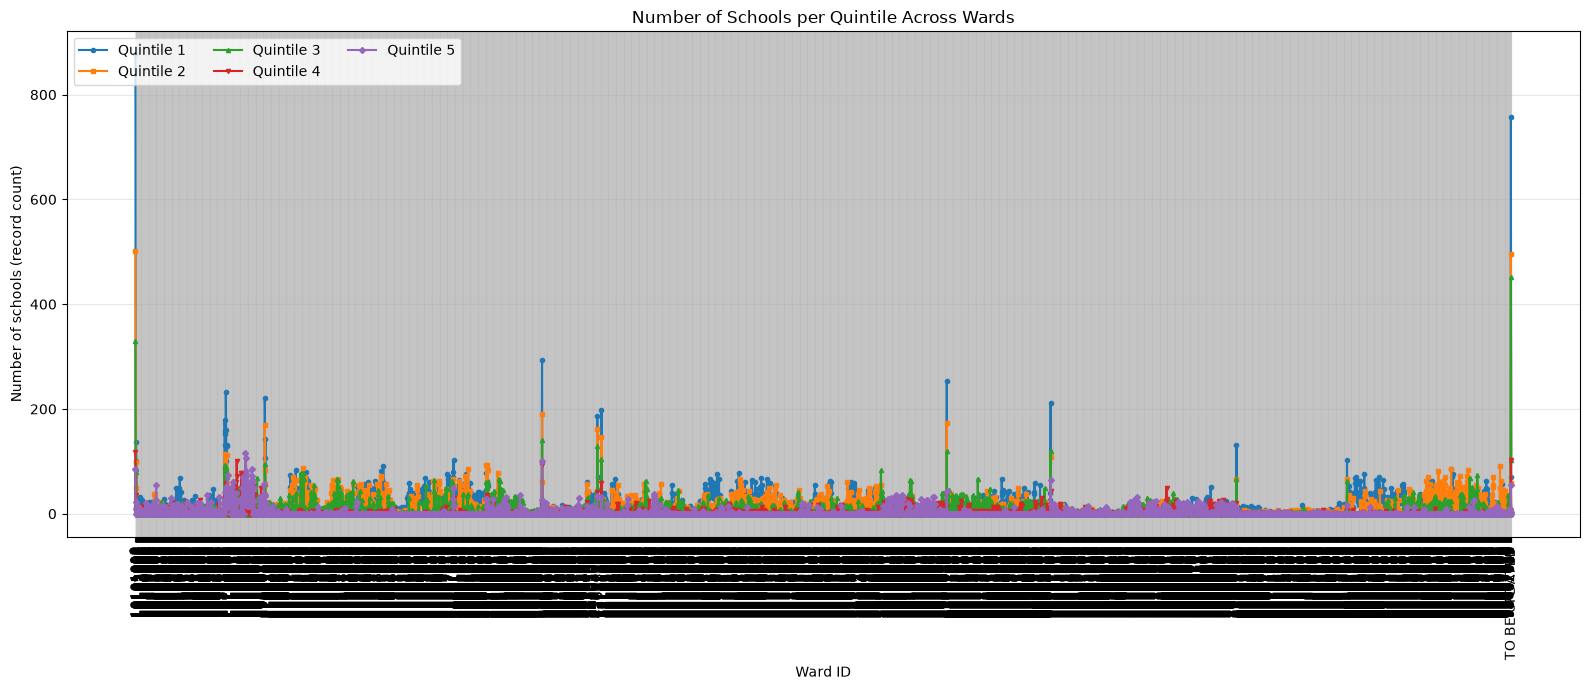

In [11]:

import pandas as pd
import matplotlib.pyplot as plt

# Load the cleaned dataset from Step 2
df = pd.read_csv(
    "step2_outputs/School_Data_Cleaned_Step2.csv"
)

# Prepare the ward and quintile columns
df["ward_id"] = df["ward_id"].astype("string").str.strip()
df["quintile"] = (
    df["quintile"].astype("string").str.strip().str.upper()
)

# Standardise Q1-Q5 if they are still present
df["quintile"] = df["quintile"].replace({
    "Q1": "1",
    "Q2": "2",
    "Q3": "3",
    "Q4": "4",
    "Q5": "5"
})

# Keep records with valid wards and standard quintiles
valid_quintiles = ["1", "2", "3", "4", "5"]

df = df[
    df["ward_id"].notna()
    & df["ward_id"].ne("")
    & df["quintile"].isin(valid_quintiles)
].copy()

# Count records per ward and quintile
counts = (
    df.groupby(["ward_id", "quintile"])
      .size()
      .unstack(fill_value=0)
      .reindex(columns=valid_quintiles, fill_value=0)
)

# Create the line plot
fig, ax1 = plt.subplots(figsize=(16, 7))

colors = [
    "#1f77b4", "#ff7f0e", "#2ca02c",
    "#d62728", "#9467bd"
]

markers = ["o", "s", "^", "v", "D"]

for i, quintile in enumerate(valid_quintiles):
    ax1.plot(
        range(len(counts)),
        counts[quintile].values,
        color=colors[i],
        marker=markers[i],
        markersize=3,
        linewidth=1.5,
        label=f"Quintile {quintile}"
    )

ax1.set_xlabel("Ward ID")
ax1.set_ylabel("Number of schools (record count)")
ax1.set_title("Number of Schools per Quintile Across Wards")

ax1.set_xticks(range(len(counts)))
ax1.set_xticklabels(counts.index, rotation=90)

ax1.legend(loc="upper left", ncol=3)
ax1.grid(alpha=0.3)

plt.tight_layout()

# Save the visualisation
plt.savefig(
    "schools_per_quintile_across_wards.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()


C:\Users\jessi\AppData\Local\Temp\ipykernel_31988\3684129814.py:10: DtypeWarning: Columns (0: emisno, 4: quintile) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(


Total records in cleaned dataset: 199,853
Records with plausible coordinates: 84,090


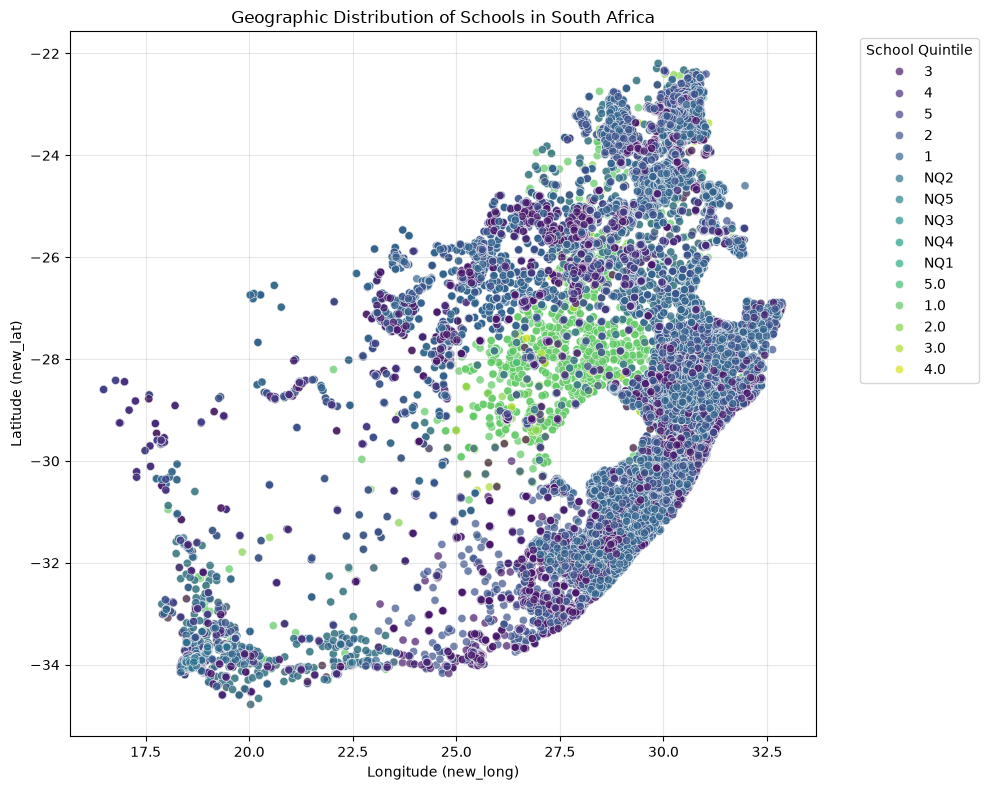

In [12]:

# Step 4: Geographic scatter plot of schools

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

# Load the cleaned dataset from Step 2
df = pd.read_csv(
    "step2_outputs/School_Data_Cleaned_Step2.csv"
)

# Convert coordinates to numeric values
df["new_long"] = pd.to_numeric(df["new_long"], errors="coerce")
df["new_lat"] = pd.to_numeric(df["new_lat"], errors="coerce")

# Remove records without usable coordinates
geo_df = df.dropna(subset=["new_long", "new_lat"]).copy()

# Keep coordinates within broad South African bounds
geo_df = geo_df[
    geo_df["new_long"].between(16, 34)
    & geo_df["new_lat"].between(-36, -22)
]

print(f"Total records in cleaned dataset: {len(df):,}")
print(f"Records with plausible coordinates: {len(geo_df):,}")

# Create the geographic scatter plot
plt.figure(figsize=(10, 8))

sns.scatterplot(
    data=geo_df,
    x="new_long",
    y="new_lat",
    hue="quintile",
    palette="viridis",
    alpha=0.7,
    s=35
)

plt.title("Geographic Distribution of Schools in South Africa")
plt.xlabel("Longitude (new_long)")
plt.ylabel("Latitude (new_lat)")
plt.legend(
    title="School Quintile",
    bbox_to_anchor=(1.05, 1),
    loc="upper left"
)

plt.grid(alpha=0.3)
plt.tight_layout()

# Save the visualisation
plt.savefig(
    "south_african_school_locations.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()


C:\Users\jessi\AppData\Local\Temp\ipykernel_31988\2585950285.py:5: DtypeWarning: Columns (4: quintile) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(


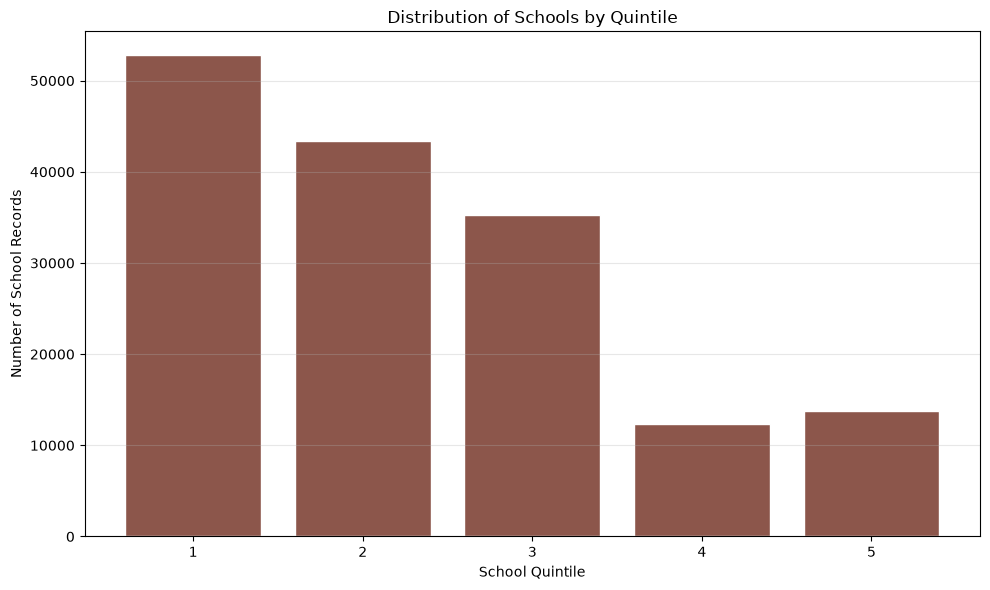

Number of school records per quintile:
quintile
1    52770
2    43325
3    35249
4    12309
5    13751
Name: count, dtype: Int64

Records included: 157,404
Records excluded due to missing/invalid quintile: 42,449


In [13]:

import pandas as pd
import matplotlib.pyplot as plt

# Load the cleaned dataset from Step 2
df = pd.read_csv(
    'step2_outputs/School_Data_Cleaned_Step2.csv',
    dtype={'emisno': str, 'centreno': str, 'ward_id': str}
)

# Standardise quintile values
df['quintile'] = (
    df['quintile']
    .astype('string')
    .str.strip()
    .str.upper()
    .replace({
        'Q1': '1', 'Q2': '2', 'Q3': '3',
        'Q4': '4', 'Q5': '5'
    })
)

# Convert quintile to numeric and keep valid values
df['quintile'] = pd.to_numeric(df['quintile'], errors='coerce')
df_valid = df[df['quintile'].isin([1, 2, 3, 4, 5])].copy()

# Count school records in each quintile
quintile_counts = (
    df_valid['quintile']
    .value_counts()
    .reindex([1, 2, 3, 4, 5], fill_value=0)
)

# Create the visualisation
plt.figure(figsize=(10, 6))

plt.bar(
    quintile_counts.index.astype(str),
    quintile_counts.values,
    color='#8c564b',
    edgecolor='white'
)

plt.title('Distribution of Schools by Quintile')
plt.xlabel('School Quintile')
plt.ylabel('Number of School Records')
plt.xticks(['1', '2', '3', '4', '5'])
plt.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig('schools_by_quintile.png', dpi=150)
plt.show()

# Display the counts used in the chart
print("Number of school records per quintile:")
print(quintile_counts)
print(f"\nRecords included: {len(df_valid):,}")
print(f"Records excluded due to missing/invalid quintile: {len(df) - len(df_valid):,}")
